# 01 · How many transits does Lazuli need to detect an atmosphere on K2-18 b and TRAPPIST-1 e?

K2-18 b (a temperate sub-Neptune around an M2.5 dwarf) and TRAPPIST-1 e (a rocky habitable-zone planet around an M8 dwarf) are the two planets everyone asks about. Both have small atmospheric signals and long-ish periods, so the transit count is the budget line. Here we forecast the H$_2$O-band S/N versus the number of transits for clear, cloudy, hazy and 100× solar atmospheres, and for TRAPPIST-1 e also ask what happens once the atmosphere is not H$_2$-dominated.

**Instrument / code:** Lazuli IFS, `lazuli_exo.observe` (showcase planets, precomputed slicersim noise) and `lazuli_exo.simulate` (mean-molecular-weight sweep).

## Prompt to try in Jupyter AI

> Using the `lazuli_exo` package (Lazuli IFS transit-spectroscopy simulator), call `lazuli_exo.observe(planet, scenario, n_transits, R=100)` for the showcase planets "K2-18 b" and "TRAPPIST-1 e" with scenarios clear, cloudy, hazy and high_metallicity.
> For n_transits from 1 to 100, compute `obs.detect()` and pull out the H2O `band_snr` and the `template_snr_diagonal`.
> Plot H2O band S/N vs number of transits (log-log), one panel per planet, one line per scenario, with a horizontal line at S/N = 5, and print a table of the transits needed to reach S/N = 5.
> Then, for TRAPPIST-1 e only, use `lazuli_exo.presets.showcase` + `lazuli_exo.simulate` to repeat the clear case for mean molecular weight mu = 2.3 (default), 5 and 10.
> Convert transits to calendar time using the orbital period from `lazuli_exo.targets.get_target`.
> State the model assumptions (isothermal, equilibrium chemistry, no systematics floor), check the depth units (fraction vs ppm), and tell me which numbers fall outside the model's validated range.

## Setup

In [1]:
### use pre-cached data, just in case SVO and STScI archive servers are down for sncosmo downloads during experimentation
### for JupyterAI experimentation, feel free to uncomment this -- any newly downloaded data will go to ~/.cache/astropy/sncosmo/ and other places
import os, shutil
MOUNT = os.path.expanduser('~/s3/schmidt-observatory-system')
SRC = f'{MOUNT}/nov26-symposium/sncosmo_data_dir'
DEST = '/home/jovyan/sncosmo_data_dir'

# Copy only if it isn't already there (skip re-copying on every run)
if not os.path.exists(DEST):
    shutil.copytree(SRC, DEST)

# set sncosmo's environment variable for its default data directory
os.environ['SNCOSMO_DATA_DIR'] = DEST

import warnings
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
# plt.style.use('gks')

import lazuli_exo
from lazuli_exo import presets
from lazuli_exo.targets import get_target

PLANETS = ["K2-18 b", "TRAPPIST-1 e"]
SCENARIOS = ["clear", "hazy", "high_metallicity", "cloudy"]   # 'flat' has zero signal by construction
COLORS = dict(clear='#00798c', hazy='#edae49', high_metallicity='#30638e', cloudy='#d1495b')
N = np.unique(np.round(np.logspace(0, 2, 15)).astype(int))   # 1 ... 100 transits
THUMB = Path('thumbs/01_k2-18b_trappist-1e_atmospheres.png')

for p in PLANETS:
    t = get_target(p)
    print(f"{p:13s} T_eq = {t['T_eq_K']:.0f} K, P = {t['period_d']:.2f} d, host T_eff = {t['T_eff_K']:.0f} K, J = {t['J_mag']:.2f}")

K2-18 b       T_eq = 284 K, P = 32.94 d, host T_eff = 3457 K, J = 9.76
TRAPPIST-1 e  T_eq = 250 K, P = 6.10 d, host T_eff = 2566 K, J = 11.35


## One transit first

The binned spectrum at R = 100, its per-bin error bar, and the band S/N from `detect()` (a matched-template S/N against a flat line, restricted to fixed band masks; not a formal detection significance).

In [2]:
for p in PLANETS:
    for sc in SCENARIOS:
        o = lazuli_exo.observe(p, sc, n_transits=1, R=100)
        d = o.detect()
        amp = o.meta['atmosphere']['feature_amplitude_ppm']
        print(f"{p:13s} {sc:17s} feature ptp = {amp:6.0f} ppm, median sigma/bin = {np.median(o.depth_err)*1e6:4.0f} ppm, "
              f"template S/N = {d['template_snr_diagonal']:5.2f}, H2O band S/N = {d['band_snr']['H2O']:5.2f}")
print('T clamped to the 300 K chemistry floor:', {p: lazuli_exo.observe(p, 'clear').meta['atmosphere'].get('T_clamped') for p in PLANETS})

K2-18 b       clear             feature ptp =    325 ppm, median sigma/bin =  105 ppm, template S/N =  4.67, H2O band S/N =  3.20
K2-18 b       hazy              feature ptp =    303 ppm, median sigma/bin =  105 ppm, template S/N =  3.22, H2O band S/N =  2.14
K2-18 b       high_metallicity  feature ptp =    210 ppm, median sigma/bin =  105 ppm, template S/N =  3.48, H2O band S/N =  2.20
K2-18 b       cloudy            feature ptp =    155 ppm, median sigma/bin =  105 ppm, template S/N =  0.37, H2O band S/N =  0.29
TRAPPIST-1 e  clear             feature ptp =   3138 ppm, median sigma/bin =  565 ppm, template S/N =  9.62, H2O band S/N =  6.70
TRAPPIST-1 e  hazy              feature ptp =   2651 ppm, median sigma/bin =  565 ppm, template S/N =  6.85, H2O band S/N =  4.74
TRAPPIST-1 e  high_metallicity  feature ptp =   1793 ppm, median sigma/bin =  565 ppm, template S/N =  6.48, H2O band S/N =  4.50
TRAPPIST-1 e  cloudy            feature ptp =   1347 ppm, median sigma/bin =  565 ppm, tem

## S/N versus number of transits

We call `observe()` at each transit count (the noise scales as $1/\sqrt{N}$, so this doubles as a check of that scaling).

In [3]:
snr = {}   # (planet, scenario) -> H2O band S/N array over N
for p in PLANETS:
    for sc in SCENARIOS:
        snr[p, sc] = np.array([lazuli_exo.observe(p, sc, n_transits=int(n), R=100).detect()['band_snr']['H2O'] for n in N])

# sanity check: S/N(N) = S/N(1) * sqrt(N)
assert all(np.allclose(s, s[0] * np.sqrt(N), rtol=1e-6) for s in snr.values())

def n_needed(snr1, target=5.0):
    return int(np.ceil((target / snr1) ** 2))

print(f"{'planet':13s} {'scenario':17s} {'H2O S/N(1)':>10s} {'N to S/N=5':>11s} {'time span [d]':>17s}")
for (p, sc), s in snr.items():
    n5 = n_needed(s[0])
    print(f"{p:13s} {sc:17s} {s[0]:10.2f} {n5:11d} {n5 * get_target(p)['period_d']:17.0f}")

planet        scenario          H2O S/N(1)  N to S/N=5     time span [d]
K2-18 b       clear                   3.20           3                99
K2-18 b       hazy                    2.14           6               198
K2-18 b       high_metallicity        2.20           6               198
K2-18 b       cloudy                  0.29         302              9948
TRAPPIST-1 e  clear                   6.70           1                 6
TRAPPIST-1 e  hazy                    4.74           2                12
TRAPPIST-1 e  high_metallicity        4.50           2                12
TRAPPIST-1 e  cloudy                  0.57          79               482


## TRAPPIST-1 e without a primordial envelope

An H$_2$-dominated atmosphere on a 0.9 R$_\oplus$ planet is the optimistic case. `simulate()` lets us override the mean molecular weight $\mu$ while keeping the same star and (live slicersim) noise. The first call takes about a minute while slicersim computes the noise for this star; it is cached afterwards. The validated range stops at $\mu$ = 15, so an N$_2$/CO$_2$ atmosphere ($\mu \approx$ 28–44) is out of reach of this model.

In [4]:
mu_snr = {}
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    for mu in (None, 5.0, 10.0):
        o = lazuli_exo.simulate({**presets.showcase('TRAPPIST-1 e', 'clear'), 'mu': mu}, R=100, n_transits=1)
        mu_snr[mu] = o.detect()['band_snr']['H2O']
        print(f"mu = {('2.3 (chem)' if mu is None else mu)!s:10s}: H2O band S/N per transit = {mu_snr[mu]:.2f} "
              f"-> {n_needed(mu_snr[mu])} transits = {n_needed(mu_snr[mu]) * get_target('TRAPPIST-1 e')['period_d']:.0f} d")

mu = 2.3 (chem): H2O band S/N per transit = 6.75 -> 1 transits = 6 d
mu = 5.0       : H2O band S/N per transit = 2.91 -> 3 transits = 18 d
mu = 10.0      : H2O band S/N per transit = 1.40 -> 13 transits = 79 d


## Hero figure

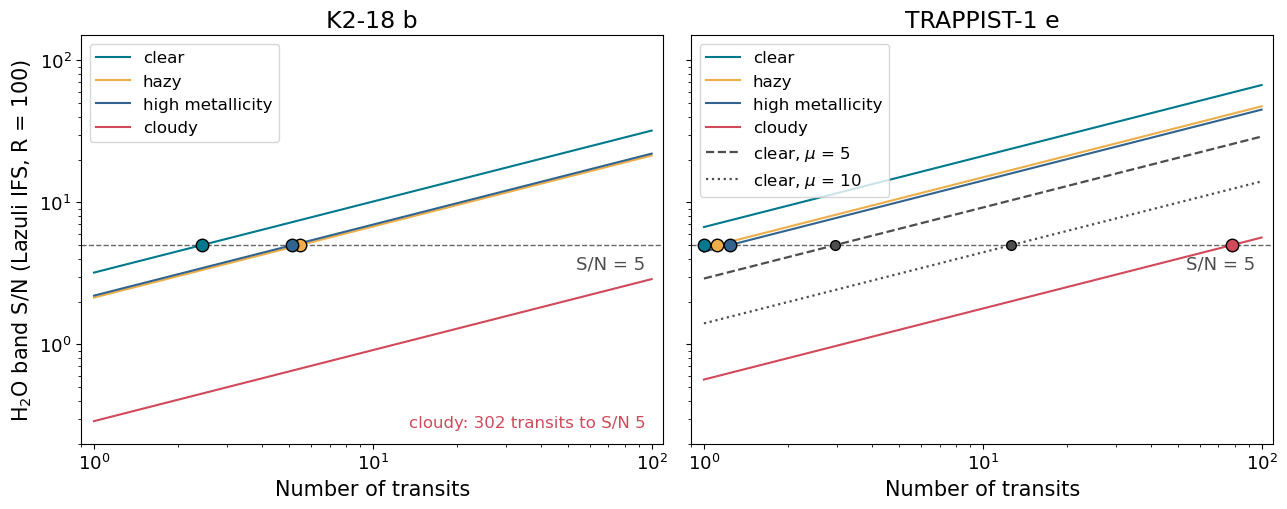

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), sharey=True)
for ax, p in zip(axes, PLANETS):
    for sc in SCENARIOS:
        s = snr[p, sc]
        ax.loglog(N, s, color=COLORS[sc], label=sc.replace('_', ' '))
        x5 = (5 / s[0]) ** 2          # continuous crossing point
        if x5 <= N[-1]:
            ax.plot(max(x5, 1), 5, 'o', color=COLORS[sc], ms=9, mec='k', zorder=5)
        else:
            ax.text(95, 0.25, f'{sc}: {n_needed(s[0])} transits to S/N 5', color=COLORS[sc], fontsize=12, ha='right', va='bottom')
    if p == 'TRAPPIST-1 e':
        for mu, ls in ((5.0, '--'), (10.0, ':')):
            ax.loglog(N, mu_snr[mu] * np.sqrt(N), color='0.3', ls=ls, lw=1.6, label=f'clear, $\\mu$ = {mu:.0f}')
            ax.plot((5 / mu_snr[mu]) ** 2, 5, 'o', color='0.3', ms=7, mec='k', zorder=5)
    ax.axhline(5, color='0.4', ls='--', lw=1)
    ax.text(95, 4.3, 'S/N = 5', color='0.3', fontsize=13, ha='right', va='top')
    ax.set_title(p, fontsize=17)
    ax.set_xlabel('Number of transits', fontsize=15)
    ax.set_xlim(0.9, 110); ax.set_ylim(0.2, 150)
    ax.tick_params(labelsize=13)
axes[0].set_ylabel('H$_2$O band S/N (Lazuli IFS, R = 100)', fontsize=15)
axes[0].legend(fontsize=12, loc='upper left')
axes[1].legend(fontsize=12, loc='upper left')
fig.tight_layout()
fig.savefig(THUMB, dpi=150)
plt.show()

A look at what the K2-18 b clear-atmosphere spectrum looks like at the transit count that reaches S/N = 5 in the H$_2$O band:

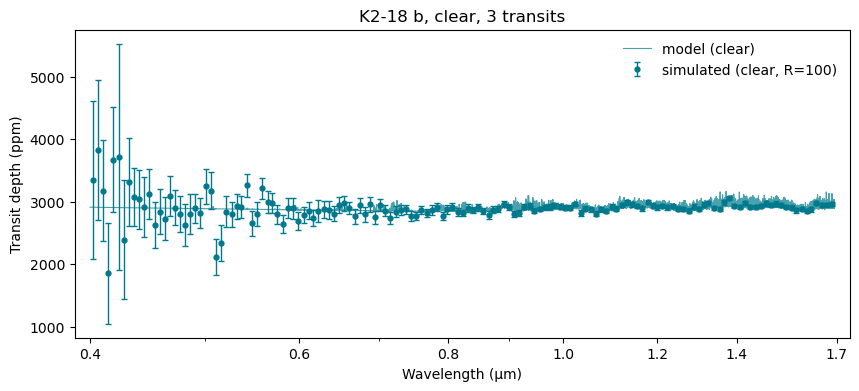

In [6]:
n5 = n_needed(snr['K2-18 b', 'clear'][0])
o = lazuli_exo.observe('K2-18 b', 'clear', n_transits=n5, R=100)
ax = o.plot(units='ppm', seed=1, color='#00798c')
ax.figure.set_size_inches(10, 4)
plt.show()

## Answer

**K2-18 b:** a clear H$_2$-rich atmosphere gives H$_2$O band S/N = 3.2 per transit, so **3 transits** reach S/N = 5 (hazy or 100× solar: 6 transits); a gray deck at 1 mbar pushes it to ~300 transits, i.e. effectively undetectable. **TRAPPIST-1 e:** an H$_2$-rich clear atmosphere would show up in **a single transit** (S/N = 6.7), but the signal falls fast with mean molecular weight: μ = 5 needs 3 transits and μ = 10 needs 13 (≈ 80 days of transits), and a cloudy H$_2$ atmosphere needs 79.

## Caveats & next steps

- **Optimistic atmospheres.** The showcase scenarios are H$_2$-rich (μ ≈ 2.3 unless metallicity raises it). Both planets sit below the 300 K floor of the chemistry grid and are clamped to 300 K. The model is a 1D isothermal, equilibrium-chemistry surrogate of POSEIDON: fine for rankings and transit counts, not for quoting a detection significance.
- **No systematics floor.** Errors scale as $1/\sqrt{N}$ forever; real stacks of tens of transits will hit a noise floor. M-dwarf PHOENIX SEDs are too bright in the blue, so the blue-end noise is ~10–25 % optimistic. Stellar contamination is off here (see notebook 03).
- **Band S/N is not a molecule detection.** The H$_2$O mask overlaps CH$_4$ near 1.15 µm and includes any continuum slope.
- *Extend it:* (1) add a systematics floor (e.g. 20 ppm per bin, added in quadrature) and see where the curves saturate; (2) fold in visibility: how many K2-18 b transits fit in a 5-year mission?; (3) bring your own petitRADTRANS/POSEIDON N$_2$- or CO$_2$-dominated spectrum via `simulate(star, spectrum=(wl, depth))` for TRAPPIST-1 e.